# Análise de dados do dataset de Parma para decidir o melhor momento de regar o tomate no projeto SIT

Este notebook analisa e prepara os dados do dataset público de Parma para o modelo da entrega v2 / marco M3, com base nas condições e limitações presentes no projeto.

A pergunta é simples: **com os sensores que a nossa estação tem (umidade do solo, temperatura e umidade do ar), dá para
dizer quando o tomateiro precisa de água?** Primeiro damos uma volta pelo dataset inteiro (como ele é organizado e o que tem nele). Depois, antes de treinar qualquer coisa, respondemos seis perguntas:

1. Que partes dele vale a pena usar, e por quê?
2. Qual sensor de solo é de 15 cm e qual é de 30 cm?
3. Como a linha escolhida foi irrigada de verdade?
4. Houve chuva que ninguém registrou?
5. Como trazer a umidade medida a 15 cm para o nosso sensor, que vai ficar a 7 cm?
6. O clima de Parma serve de referência para Fortaleza?

No fim, o notebook salva uma tabela limpa (`data/processed/linha3_10min.csv`) que o notebook de modelagem vai usar.

## 1. Visão geral do dataset

*IoT Dataset from an Evolving Tomato Cultivation Testbed* (Oddi, Belli, Davoli e outros, Universidade de Parma,
[Mendeley Data](https://data.mendeley.com/datasets/h8sfcf9487/2)). É uma fazenda experimental de tomate (HEINZ 1301) em Parma, na Itália,
acompanhada por sensores LoRaWAN em três safras: 2023, 2024 e 2025.

**Como está organizado.** Uma pasta por ano. Dentro de cada pasta, um CSV por tipo de medida e um `README.md` que descreve os arquivos.
Todos seguem o mesmo formato "longo": uma linha por leitura, com o horário (`ts_generation`, em milissegundos desde 1970, em UTC), o código do
dispositivo (`generated_by`), a linha de plantio (`line`, de 1 a 5, e 0 para dispositivos gerais) e o valor medido. Os sensores mandam uma leitura a cada 10 minutos.
Os índices agronômicos são diários. Os arquivos de 2024 e 2025 têm cinco linhas de plantas, cada uma com um tratamento de irrigação diferente.

Abaixo, o inventário de tudo que existe, calculado direto dos arquivos.

In [1]:
import json, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)

# acha a raiz do repositório (a pasta que tem data/)
raiz = Path.cwd()
while not (raiz / "data").exists() and raiz != raiz.parent:
    raiz = raiz.parent
DATA = raiz / "data" / "IoT Dataset from an Evolving Tomato Cultivation Te"
if (DATA / DATA.name).is_dir():          # alguns extratores criam uma pasta a mais
    DATA = DATA / DATA.name
EXTERNO, PROCESSADO = raiz / "data" / "externo", raiz / "data" / "processed"
EXTERNO.mkdir(exist_ok=True); PROCESSADO.mkdir(exist_ok=True)

def ler(ano, arquivo):
    # os horários do dataset estão em UTC (milissegundos desde 1970)
    df = pd.read_csv(DATA / str(ano) / f"{arquivo}{ano}.csv")
    df["t"] = pd.to_datetime(df["ts_generation"], unit="ms")
    return df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")])

def vpd(temp, ur):
    # déficit de pressão de vapor (kPa): quanto o ar "puxa" água. Quanto maior, mais seca o solo e a planta
    es = 0.6108 * np.exp(17.27 * temp / (temp + 237.3))
    return es * (1 - ur / 100)

ANOS = (2024, 2025)
LINHA = 3

In [2]:
DESCRICAO = {
    "environmental":    "ar da fazenda: CO₂, pressão, temperatura e umidade",
    "soil":             "solo: umidade, temperatura e condutividade (2 sensores por linha)",
    "valve_controller": "válvula de cada linha: aberta ou fechada",
    "water_valve":      "válvula (2023): estado e temperaturas",
    "water_meter":      "hidrômetro: volume acumulado de água por linha",
    "water_potential":  "potencial hídrico do solo",
    "pressure":         "pressão da água na tubulação",
    "leaf_temperature": "temperatura da folha",
    "stem":             "diâmetro do caule",
    "fruit":            "tamanho do fruto",
    "indicators":       "índices agronômicos diários (graus-dia)",
}
inv = []
for ano in (2023, 2024, 2025):
    for arq in sorted((DATA / str(ano)).glob("*.csv")):
        nome = arq.stem.replace(str(ano), "")
        d = pd.read_csv(arq)
        t_ = pd.to_datetime(d["ts_generation"], unit="ms")
        valores = [c for c in d.columns if c not in ("ts_generation", "generated_by", "device_identifier", "line") and not c.startswith("Unnamed")]
        disp = "generated_by" if "generated_by" in d else ("device_identifier" if "device_identifier" in d else None)
        inv.append({"ano": ano, "arquivo": nome, "o que mede": DESCRICAO[nome], "linhas de dados": len(d),
                    "dispositivos": d[disp].nunique() if disp else "-",
                    "de": t_.min().date(), "até": t_.max().date()})
inv = pd.DataFrame(inv)
inv

,ano,arquivo,o que mede,linhas de dados,dispositivos,de,até
0,2023,environmental,"ar da fazenda: CO₂, pressão, temperatura e umi...",10964,1,2023-06-29,2023-09-13
1,2023,indicators,índices agronômicos diários (graus-dia),118,-,2023-06-29,2023-10-24
2,2023,soil,"solo: umidade, temperatura e condutividade (2 ...",47894,3,2023-06-06,2023-10-18
3,2023,water_meter,hidrômetro: volume acumulado de água por linha,50734,3,2023-06-15,2023-10-25
4,2023,water_valve,válvula (2023): estado e temperaturas,75539,3,2023-06-20,2023-12-31
5,2024,environmental,"ar da fazenda: CO₂, pressão, temperatura e umi...",9327,1,2024-06-12,2024-09-05
6,2024,indicators,índices agronômicos diários (graus-dia),205,-,2024-01-18,2024-09-05
7,2024,pressure,pressão da água na tubulação,155163,11,2024-06-10,2024-09-25
8,2024,soil,"solo: umidade, temperatura e condutividade (2 ...",182153,10,2023-06-06,2024-09-23
9,2024,valve_controller,válvula de cada linha: aberta ou fechada,64047,5,2024-06-10,2024-09-19


O que dá para ver:

- **O conjunto de sensores cresce a cada ano.** 2023 tem só ar, solo, hidrômetro e válvula (além dos índices diários). 2024 acrescenta pressão e potencial hídrico. 2025 acrescenta folha, caule e fruto.
- **Solo e ar são o que a nossa estação também mede.** O solo tem 10 sensores por ano em 2024 e 2025 (2 por linha) e 3 em 2023 (1 por linha). A válvula e o hidrômetro dizem *quando* e *quanto* cada linha foi irrigada.
- **As datas dos arquivos não coincidem com o ano da pasta.** O `soil2024.csv` começa em junho de 2023: ele repete as leituras de 2023. Os arquivos de folha, caule e fruto de 2025 vão até janeiro de 2026 (o de fruto começa em 31/12/2024).
  Por isso, sempre filtramos pelo horário, não pelo nome do arquivo.
- **Cada tipo de sensor tem uma cobertura diferente.** O ar começa em junho e termina entre setembro e outubro. O solo e a válvula têm períodos próprios. Só conseguimos usar o que existe nos três ao mesmo tempo.

Uma olhada geral em dois sinais de cada safra, o ar da fazenda e a umidade do solo de cada linha (média diária dos sensores da linha):

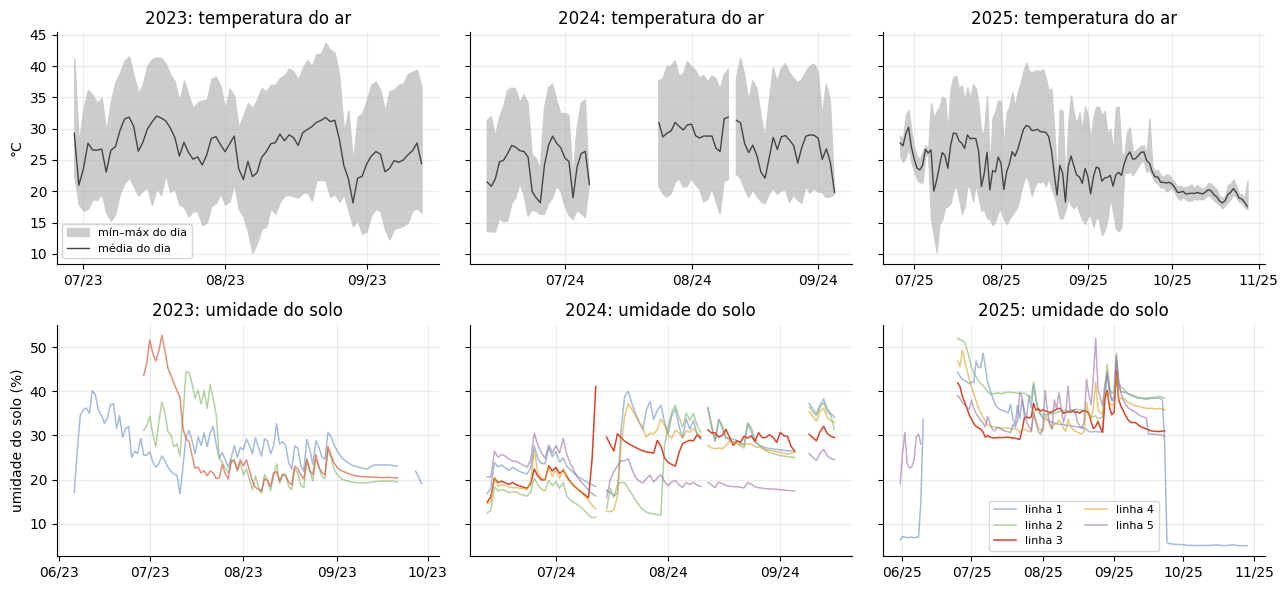

In [3]:
import matplotlib.dates as mdates
fig, eixos = plt.subplots(2, 3, figsize=(13, 6), sharey="row")
cores = {1: "#6c8ebf", 2: "#82b366", 3: "#d2452c", 4: "#d6a229", 5: "#9673a6"}
for j, ano in enumerate((2023, 2024, 2025)):
    e = ler(ano, "environmental")
    e = e[e.t.dt.year == ano].set_index("t").temperature.resample("D")
    eixos[0, j].fill_between(e.min().index, e.min(), e.max(), color="#cccccc", label="mín–máx do dia")
    eixos[0, j].plot(e.mean(), color="#444", lw=1, label="média do dia")
    eixos[0, j].set_title(f"{ano}: temperatura do ar")
    s = ler(ano, "soil")
    s = s[(s.t.dt.year == ano) & (s.humidity > 5) & (s.humidity <= 100)]
    for ln, g in s.groupby("line"):
        eixos[1, j].plot(g.set_index("t").humidity.resample("D").mean(), color=cores[ln], lw=1.1,
                         label=f"linha {ln}", alpha=1 if ln == 3 and ano > 2023 else .6)
    eixos[1, j].set_title(f"{ano}: umidade do solo")
    for k in (0, 1):
        eixos[k, j].xaxis.set_major_locator(mdates.MonthLocator())
        eixos[k, j].xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
eixos[0, 0].set_ylabel("°C"); eixos[1, 0].set_ylabel("umidade do solo (%)")
eixos[0, 0].legend(fontsize=8); eixos[1, 2].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

O que se vê: o verão de Parma é quente (a média mensal fica acima de 25 °C em julho e agosto dos três anos) e o ar varia bastante entre o dia e a noite. Os dados têm buracos, como o do ar em julho de 2024 (cerca de duas semanas), e no fim de setembro de 2025
os sensores de solo vão a quase 5 %, quando a safra termina. A umidade do solo muda de linha para linha por causa do tratamento de irrigação, que é justamente o que queremos entender. O experimento mudou de um ano para o outro, e isso decide o que podemos usar.

## 2. Os três anos de experimento

O experimento mudou de um ano para o outro, e isso é o que mais importa para nós:

| Ano | Linhas | Como cada linha foi irrigada | Sensores de solo |
|---|---|---|---|
| 2023 | 3 | 100 %, 60 % e 30 % da recomendação do Irriframe, manual pelo agricultor | 1 por linha, a 20 cm |
| 2024 | 5 | linha 1: 80 %, linha 2: 60 %, **linha 3: limiar de umidade do solo**, linha 4: 100 %, linha 5: 30 % | 2 por linha (15 e 30 cm) |
| 2025 | 5 | linha 1: 100 %, linha 2: 30 %, **linha 3: limiar de umidade do solo**, linha 4: limiar de temperatura da folha, linha 5: estratégia de IA | 2 por linha (15 e 30 cm) |

O Irriframe é um serviço italiano de recomendação de irrigação. Fontes: página do dataset no Mendeley (regimes por
linha) e o README de cada pasta (sensores e profundidades). A página do dataset não cita nenhum artigo, e não encontramos outro sobre as safras de 2024 e 2025. Por isso as informações vêm só da página e dos READMEs. O artigo *Smart agriculture dataset in a tomato cultivation under different irrigation regimes* (Belli et al., 2025) descreve a safra de 2023 com os sensores de 20 cm, e usamos só como contexto.

## 3. O que vamos usar: 2024 e 2025, linha 3

**Por que só 2024 e 2025.** Em 2023 não há nenhuma linha irrigada por umidade do solo, e o solo foi medido em um único ponto, a 20 cm,
com a rega feita à mão. Só em 2024 e 2025 existe uma linha em que a válvula abre quando o sensor de solo diz que está seco. Esses
dois anos também têm os dois sensores de solo por linha e o sensor de ar na mesma fazenda.

**Por que só a linha 3.** Nossa estação decide com a umidade do solo. As linhas 1, 2, 4 e 5 foram irrigadas por uma
porcentagem da recomendação do Irriframe (que vem de um modelo de evapotranspiração), pela temperatura da folha ou por um modelo de IA.
Se treinássemos com elas, o modelo aprenderia a imitar outros critérios, que a nossa estação nem mede. A linha 3 é a única em que
o motivo de cada rega aparece nos dados: o solo chegou a um valor e a válvula abriu.

Um limite do dataset: ele não tem produtividade nem qualidade do fruto. Então "o melhor momento" aqui significa
"o momento em que a regra de umidade da linha 3 mandou regar", que é uma regra de especialistas, mas não é provada como a ótima.

Para ter uma noção do que há em cada ano na linha 3:

In [4]:
resumo = []
for ano in ANOS:
    s, v, a, e = (ler(ano, n) for n in ("soil", "valve_controller", "water_meter", "environmental"))
    for nome, df in (("solo", s[s.line == LINHA]), ("válvula", v[v.line == LINHA]),
                     ("medidor de água", a[a.line == LINHA]), ("ar (fazenda toda)", e)):
        df = df[df.t.dt.year == ano]
        resumo.append({"ano": ano, "dado": nome, "registros": len(df),
                       "primeiro": df.t.min().date(), "último": df.t.max().date()})
pd.DataFrame(resumo)

,ano,dado,registros,primeiro,último
0,2024,solo,26764,2024-06-11,2024-09-23
1,2024,válvula,11658,2024-06-12,2024-09-05
2,2024,medidor de água,13186,2024-06-10,2024-10-01
3,2024,ar (fazenda toda),9327,2024-06-12,2024-09-05
4,2025,solo,39781,2025-05-31,2025-11-03
5,2025,válvula,22692,2025-06-06,2025-12-12
6,2025,medidor de água,25260,2025-06-01,2025-12-31
7,2025,ar (fazenda toda),17318,2025-06-26,2025-10-28


## 4. Organizando os dados da linha 3

O dataset vem em um CSV por tipo de medida. Dos nove arquivos de 2025 e sete de 2024, a gente só precisa de quatro: `soil` (umidade e temperatura
do solo), `environmental` (temperatura e umidade do ar), `valve_controller` (válvula aberta ou fechada) e `water_meter`
(volume de água). Pressão, folha, caule e fruto ficam de fora, porque a nossa estação não tem esses sensores.

Antes de juntar, o que encontramos de errado nos dados do solo:

In [5]:
solo = {}
linhas = []
for ano in ANOS:
    s = ler(ano, "soil")
    outro_ano = (s.t.dt.year != ano).sum()
    s = s[(s.line == LINHA) & (s.t.dt.year == ano)].copy()
    s["sensor"] = s.generated_by.str[:6]          # os dois sensores da linha, pelo início do código
    solo[ano] = s
    for sensor, g in s.groupby("sensor"):
        lac = g.sort_values("t").t.diff()
        linhas.append({"ano": ano, "sensor": sensor, "leituras": len(g),
                       "umidade = 0": int((g.humidity == 0).sum()),
                       "umidade < 5 %": int((g.humidity < 5).sum()),
                       "ausentes": int(g.humidity.isna().sum()),
                       "buracos > 1 h": int((lac > pd.Timedelta("1h")).sum()),
                       "maior buraco (h)": round(lac.max() / pd.Timedelta("1h"))})
    print(f"{ano}: o arquivo soil{ano}.csv tem {outro_ano} leituras de outros anos (nenhuma da linha 3). A linha 3 ficou com {len(s)}")
pd.DataFrame(linhas)

2024: o arquivo soil2024.csv tem 47895 leituras de outros anos (nenhuma da linha 3). A linha 3 ficou com 26764


2025: o arquivo soil2025.csv tem 0 leituras de outros anos (nenhuma da linha 3). A linha 3 ficou com 39781


,ano,sensor,leituras,umidade = 0,umidade < 5 %,ausentes,buracos > 1 h,maior buraco (h)
0,2024,2f2ba9,13334,119,1043,23,9,105
1,2024,901b4b,13430,119,1032,24,7,105
2,2025,2f2ba9,20494,0,8059,0,7,197
3,2025,901b4b,19287,0,6863,0,7,198


O que isso diz e o que fizemos:

- **Linhas de outro ano.** O `soil2024.csv` traz leituras de 2023. Filtramos pelo ano do horário.
- **Valores muito baixos (0 a 5 %).** Aparecem no começo e no fim de cada safra. Não parecem solo seco, e sim sensor fora do solo: a mediana diária dos dois sensores
  da linha 3 se divide em dois grupos sem nada no meio. Em 2025 são 59 dias abaixo de 5 % e 91 acima de 20 %. Em 2024, 8 dias abaixo de 5 % e todos os outros acima de 14,9 %.
  Solo que seca passaria por valores intermediários. O dataset não registra quando os sensores foram instalados ou retirados, então isso é uma leitura dos dados.
  Definimos a **janela ativa** de cada ano como os dias em que a mediana dos dois sensores passa de 10 %. Qualquer corte entre 5 e 12 % dá exatamente a mesma janela
  (12/06 a 15/09 em 2024 e 25/06 a 23/09 em 2025), então o 10 % só marca um ponto dentro do vazio entre os grupos.
- **Umidade 0.** São 119 leituras em cada sensor, quase todas dos primeiros dias de junho de 2024. Tratamos como dado ausente.
- **Buracos.** A frequência normal é de 10 minutos, mas há paradas de mais de uma hora (a maior tem 105 h em 2024 e 198 h em 2025). Preenchemos só buracos de até 30 minutos, por interpolação. Os maiores ficam vazios e são marcados.
  O corte de 30 minutos separa dois tipos de falha: perder uma ou duas mensagens (de 15 a 30 minutos, entre 158 e 255 casos por sensor) e uma queda de verdade do sistema (mais de 1 hora, só 7 a 9 por sensor).
  Como a umidade do solo varia em mediana de 0,05 a 0,07 ponto em 1 hora, interpolar 30 minutos não inventa nada.
- **Horário.** Os dois sensores de uma linha não enviam no mesmo instante, então arredondamos tudo para uma grade de 10 minutos.
- **Erros de codificação.** O dataset tem valores impossíveis em outras linhas (umidade de 655,35 %, igual a 65535/100, um código de erro). Na linha 3 não aparecem, mas o filtro
  (`0 < umidade <= 100`) fica no código.

## 5. Qual sensor é de 15 cm e qual é de 30 cm?

O README diz que há dois sensores por linha, um a 15 cm e outro a 30 cm, mas não diz qual código é qual. Como a profundidade
muda tudo (o sensor raso reage mais rápido a rega e a calor), precisamos descobrir pelos dados. Dois indícios físicos:

- **Temperatura do solo.** Perto da superfície a temperatura oscila mais ao longo do dia. O sensor com maior variação diária é o mais raso.
- **Resposta à rega.** A água chega primeiro ao sensor raso. Medimos quantos minutos depois da válvula abrir a umidade sobe 1 ponto (a umidade varia em mediana 0,05 ponto em 30 minutos, então 1 ponto é bem acima da oscilação normal).

Testamos em todas as 5 linhas, para ver se a regra se sustenta:

In [6]:
def perfil_sensores(ano, ini, fim):
    s = ler(ano, "soil")
    s = s[(s.t.dt.year == ano) & (s.t >= ini) & (s.t <= fim) & (s.humidity > 10) & (s.humidity <= 100)].copy()
    s["sensor"] = s.generated_by.str[:6]
    v = ler(ano, "valve_controller").sort_values("t")
    saida = []
    for ln, gl in s.groupby("line"):
        vl = v[v.line == ln]
        aberturas = vl.t[(vl.valve_state == 1) & (vl.valve_state.shift(1) != 1)]
        aberturas = aberturas[(aberturas >= ini) & (aberturas <= fim)]
        for sensor, g in gl.groupby("sensor"):
            g = g.sort_values("t").set_index("t")
            amp = g.temperature.resample("D").agg(lambda x: x.max() - x.min() if len(x) > 100 else np.nan).mean()
            atrasos = []
            for t0 in aberturas:
                antes = g.humidity[t0 - pd.Timedelta("20min"):t0]
                depois = g.humidity[t0:t0 + pd.Timedelta("3h")]
                if len(antes) and len(depois) >= 6:
                    subiu = depois[depois >= antes.iloc[-1] + 1]
                    if len(subiu):
                        atrasos.append((subiu.index[0] - t0).total_seconds() / 60)
            saida.append({"ano": ano, "linha": ln, "sensor": sensor, "amplitude_temp_solo": amp,
                          "atraso_resposta_min": np.median(atrasos) if atrasos else np.nan})
    return pd.DataFrame(saida)

perfil = pd.concat([perfil_sensores(a, f"{a}-07-15", f"{a}-09-15") for a in ANOS], ignore_index=True)
# regra: dentro de cada linha, a maior oscilação de temperatura = sensor raso (15 cm)
raso = perfil.groupby(["ano", "linha"]).amplitude_temp_solo.transform("max") == perfil.amplitude_temp_solo
perfil["profundidade_estimada"] = np.where(raso, 15, 30)
perfil.round(2)

,ano,linha,sensor,amplitude_temp_solo,atraso_resposta_min,profundidade_estimada
0,2024,1,0fa420,2.50,14.88,15
1,2024,1,91738f,0.92,53.98,30
2,2024,2,908aff,0.74,47.18,30
3,2024,2,9d5fe8,2.20,28.26,15
4,2024,3,2f2ba9,0.67,30.60,30
5,2024,3,901b4b,1.98,14.87,15
6,2024,4,1bc7a8,2.32,111.35,15
7,2024,4,28f971,1.09,136.58,30
8,2024,5,0da903,0.87,46.83,30
9,2024,5,19b4d9,2.57,26.65,15


In [7]:
# os códigos dos sensores se repetem de um ano para o outro? E a regra concorda com o tempo de resposta?
pares = perfil.pivot_table(index=["ano", "linha"], columns="profundidade_estimada",
                           values=["atraso_resposta_min"]).dropna()
pares.columns = ["raso_min", "fundo_min"]
print(f"o sensor raso responde antes do fundo em {(pares.raso_min < pares.fundo_min).sum()} de {len(pares)} pares com dados")

mesmo = perfil.pivot(index=["linha", "sensor"], columns="ano", values="profundidade_estimada").dropna()
print(f"o mesmo código ficou na mesma profundidade nos dois anos em {(mesmo[2024] == mesmo[2025]).sum()} de {len(mesmo)} sensores")

PROF = perfil[perfil.linha == LINHA].set_index(["ano", "sensor"]).profundidade_estimada
print("\nlinha 3:"); print(PROF.to_string())

o sensor raso responde antes do fundo em 7 de 8 pares com dados
o mesmo código ficou na mesma profundidade nos dois anos em 10 de 10 sensores

linha 3:
ano   sensor
2024  2f2ba9    30
      901b4b    15
2025  2f2ba9    30
      901b4b    15


A regra se sustenta. O sensor com maior oscilação de temperatura também responde primeiro à rega em 7 dos 8 pares em que a resposta pôde ser medida. A exceção é a linha 4 de
2025, um empate prático (13,5 contra 12,4 minutos). Nas linhas 2 e 5 de 2025 não houve resposta mensurável à rega (as válvulas quase não abriram). E cada código manteve a mesma profundidade nos dois anos.
**Na linha 3, `901b4b` é o sensor de 15 cm e `2f2ba9` é o de 30 cm**, e o atraso de resposta confirma: 15 min contra 31 min em 2024, 26 min contra 96 min em 2025.

Isso é uma estimativa feita pelos dados, não uma informação do dataset. Vale confirmar com os autores, mas dois indícios independentes apontam para o mesmo resultado.

## 6. A tabela de 10 minutos

Agora juntamos tudo em uma tabela só por ano: dois sensores de solo (umidade e temperatura), temperatura e umidade do ar, a válvula
da linha 3 e o volume de água do medidor da linha. Calculamos também o VPD (déficit de pressão de vapor), que resume em um número o quanto
o ar está "puxando" água, e a hora local de Parma (o dataset está em UTC).

In [8]:
def episodios(ano, linha, intervalo="60min"):
    # a válvula abre e fecha várias vezes seguidas, e juntamos aberturas separadas por menos de 1 h em uma "rega"
    v = ler(ano, "valve_controller")
    v = v[v.line == linha].sort_values("t")
    aberta, abre = [], None
    for t, estado in zip(v.t, v.valve_state):
        if estado == 1 and abre is None:
            abre = t
        elif estado == 0 and abre is not None:
            aberta.append((abre, t)); abre = None
    ab = pd.DataFrame(aberta, columns=["ini", "fim"])
    ab["rega"] = ((ab.ini - ab.fim.shift()) > pd.Timedelta(intervalo)).cumsum()
    return ab

def montar_base(ano):
    s = solo[ano].copy()
    s["umid"] = s.humidity.where((s.humidity > 0) & (s.humidity <= 100))
    s["prof"] = s.sensor.map(lambda x: PROF[(ano, x)])
    s["t10"] = s.t.dt.round("10min")
    g = s.groupby(["t10", "prof"]).agg(umid=("umid", "mean"), temp=("temperature", "mean")).unstack()
    g.columns = [f"{var}_solo_{p}cm" for var, p in g.columns]

    # janela ativa: dias em que o solo está com planta (mediana diária dos dois sensores > 10 %)
    dia = g[["umid_solo_15cm", "umid_solo_30cm"]].mean(axis=1).resample("D").median()
    ativos = dia[dia > 10].index
    idx = pd.date_range(ativos.min(), ativos.max() + pd.Timedelta("23h50min"), freq="10min")
    b = g.reindex(idx)
    b.index.name = "t"
    b = b.interpolate(limit=3, limit_area="inside")        # só buracos de até 30 min

    e = ler(ano, "environmental")
    e["t10"] = e.t.dt.round("10min")
    e = e.groupby("t10")[["temperature", "humidity"]].mean().rename(columns={"temperature": "temp_ar", "humidity": "umid_ar"})
    b = b.join(e)
    b[["temp_ar", "umid_ar"]] = b[["temp_ar", "umid_ar"]].interpolate(limit=6, limit_area="inside")
    b["vpd_kpa"] = vpd(b.temp_ar, b.umid_ar)

    ab = episodios(ano, LINHA, "0min")
    b["valvula"] = False
    for ini, fim in zip(ab.ini, ab.fim):
        b.loc[ini.round("10min"):fim.round("10min"), "valvula"] = True

    a = ler(ano, "water_meter")
    vol = a[a.line == LINHA].set_index("t").current_volume.sort_index()
    vol = vol[~vol.index.duplicated()].resample("10min").max().reindex(b.index).ffill()
    b["litros"] = vol.diff().clip(lower=0).fillna(0)

    b["hora_local"] = b.index.tz_localize("UTC").tz_convert("Europe/Rome").hour
    b["ano"] = ano
    return b

base = {ano: montar_base(ano) for ano in ANOS}
for ano, b in base.items():
    print(f"{ano}: {b.index.min():%d/%m} a {b.index.max():%d/%m}  |  {len(b)} linhas de 10 min  |  "
          f"solo sem dado: {b.umid_solo_15cm.isna().mean():.1%}  |  ar sem dado: {b.temp_ar.isna().mean():.1%}")

2024: 12/06 a 15/09  |  13824 linhas de 10 min  |  solo sem dado: 9.9%  |  ar sem dado: 31.3%
2025: 25/06 a 23/09  |  13104 linhas de 10 min  |  solo sem dado: 3.0%  |  ar sem dado: 3.5%


## 7. Como a linha 3 foi irrigada de verdade

A página do dataset no Mendeley diz que a linha 3 foi irrigada por "limiar de umidade do solo", mas não diz qual limiar, nem quando ele começou a valer. Olhando cada rega, com a
umidade dos dois sensores **no momento em que a válvula abriu**:

In [9]:
def tabela_regas(ano):
    b = base[ano]
    ab = episodios(ano, LINHA)
    r = ab.groupby("rega").agg(ini=("ini", "min"), fim=("fim", "max"), aberturas=("ini", "size"))
    r["duracao_min"] = ((r.fim - r.ini) / pd.Timedelta("1min")).round()
    r["umid_15_antes"] = [b.umid_solo_15cm.asof(t) for t in r.ini]
    r["umid_30_antes"] = [b.umid_solo_30cm.asof(t) for t in r.ini]
    r["pico_15_em_3h"] = [b.umid_solo_15cm[t:t + pd.Timedelta("3h")].max() for t in r.ini]
    # valor "assentado": média entre 1,5 h e 2,5 h depois do início da rega, quando a água já se distribuiu
    r["assentada_15"] = [b.umid_solo_15cm[t + pd.Timedelta("90min"):t + pd.Timedelta("150min")].mean() for t in r.ini]
    r["assentada_30"] = [b.umid_solo_30cm[t + pd.Timedelta("90min"):t + pd.Timedelta("150min")].mean() for t in r.ini]
    a = ler(ano, "water_meter")
    vol = a[a.line == LINHA].set_index("t").current_volume.sort_index()
    vol = vol[~vol.index.duplicated()]
    r["litros"] = [vol.asof(f + pd.Timedelta("10min")) - vol.asof(i - pd.Timedelta("1min")) for i, f in zip(r.ini, r.fim)]
    return r.reset_index(drop=True)

regas = {ano: tabela_regas(ano) for ano in ANOS}
VIRADA = {2024: ("2024-08-03", "2024-08-08"), 2025: ("2025-07-22", "2025-07-25")}   # janelas só para mostrar a virada
for ano in ANOS:
    r = regas[ano]
    print(f"{ano}: {len(r)} regas entre {r.ini.min():%d/%m} e {r.ini.max():%d/%m}")
    a, b = VIRADA[ano]
    v = r[(r.ini >= a) & (r.ini <= b)]
    print("regas na virada para o controle estável:")
    print(v.assign(ini=v.ini.dt.strftime("%d/%m %H:%M")).drop(columns=["fim"]).round(1).to_string(index=False))
    print()

2024: 49 regas entre 05/07 e 03/09
regas na virada para o controle estável:
        ini  aberturas  duracao_min  umid_15_antes  umid_30_antes  pico_15_em_3h  assentada_15  assentada_30  litros
04/08 13:08          2         70.0           20.9           24.5           43.4          33.0          32.6     538
05/08 12:48          1         30.0           24.2           27.0           42.0          30.9          31.2     209
06/08 12:58          2         50.0           24.1           26.9           40.6          32.9          32.8     351
07/08 12:58          1         30.0           24.4           26.9           40.8          30.9          30.9     261

2025: 58 regas entre 06/06 e 19/08
regas na virada para o controle estável:
        ini  aberturas  duracao_min  umid_15_antes  umid_30_antes  pico_15_em_3h  assentada_15  assentada_30  litros
23/07 09:38          6        230.0           28.0           30.1           30.6          28.4          30.2  1559.0
23/07 16:38          1      

Duas fases bem diferentes aparecem em cada ano:

- **Começo da safra: testes e regas manuais.** Regas de 1 minuto, de 14 minutos, de 200 minutos, séries de regas seguidas, umidade
  de abertura que muda a cada vez. Não é um controle por limiar.
- **Depois: controle estável.** Cada rega dura 30 minutos (as mais longas são duas aberturas seguidas) e a válvula abre sempre com a umidade quase no mesmo
  valor. É isso que queremos aprender.

Fixamos a fase de controle pelas datas em que a umidade de abertura passa a ser constante (5/8 a 3/9 em 2024 e de 23/7, a partir das 16 h, a 19/8 em 2025, e depois dessas datas
a válvula da linha 3 não abre mais). A tabela acima mostra a virada. Em 2024, a rega de 4/8 (70 minutos, sensor de 30 cm a 24,5 %) ainda é de teste e a de 5/8 já abre com 27,0 %.
Em 2025, a rega de 23/7 às 9 h 38 (230 minutos, 15 cm a 28,0 %) é de teste e a das 16 h 38 já abre com 33,9 %, valor que se repete nas regas seguintes. Uma "rega" aqui junta aberturas separadas por menos de 1 hora: dos 147 intervalos entre aberturas da linha 3, 39 têm menos de 20 minutos, 103 têm 2 horas ou mais e só 5 ficam no meio, então 1 hora separa bem os dois casos. Para saber qual sensor manda na válvula,
comparamos a dispersão do valor de abertura nos dois sensores.

In [10]:
FASE_CONTROLE = {2024: ("2024-08-05", "2024-09-03 23:50"), 2025: ("2025-07-23 16:00", "2025-08-19 23:50")}

for ano in ANOS:
    b, r = base[ano], regas[ano]
    ini, fim = map(pd.Timestamp, FASE_CONTROLE[ano])
    b["fase"] = np.where((b.index >= ini) & (b.index <= fim), "controle", "outra")
    c = r[(r.ini >= ini) & (r.ini <= fim)]
    print(f"{ano}: fase de controle {ini:%d/%m} a {fim:%d/%m} ({(fim - ini).days + 1} dias), {len(c)} regas")
    print(f"   umidade antes de abrir (mediana ± desvio): 15 cm = {c.umid_15_antes.median():.1f} ± {c.umid_15_antes.std():.1f}"
          f"   |   30 cm = {c.umid_30_antes.median():.1f} ± {c.umid_30_antes.std():.1f}")
    print(f"   rega típica: {c.duracao_min.median():.0f} min, {c.litros.median():.0f} litros. No sensor de 15 cm a umidade sobe "
          f"{(c.pico_15_em_3h - c.umid_15_antes).median():.1f} pontos no pico e {(c.assentada_15 - c.umid_15_antes).median():.1f} depois de 2 h")

2024: fase de controle 05/08 a 03/09 (30 dias), 38 regas
   umidade antes de abrir (mediana ± desvio): 15 cm = 26.8 ± 1.5   |   30 cm = 26.9 ± 0.5
   rega típica: 30 min, 264 litros. No sensor de 15 cm a umidade sobe 13.2 pontos no pico e 6.1 depois de 2 h
2025: fase de controle 23/07 a 19/08 (28 dias), 53 regas
   umidade antes de abrir (mediana ± desvio): 15 cm = 33.9 ± 0.1   |   30 cm = 33.9 ± 1.0
   rega típica: 30 min, 211 litros. No sensor de 15 cm a umidade sobe 12.5 pontos no pico e 4.7 depois de 2 h


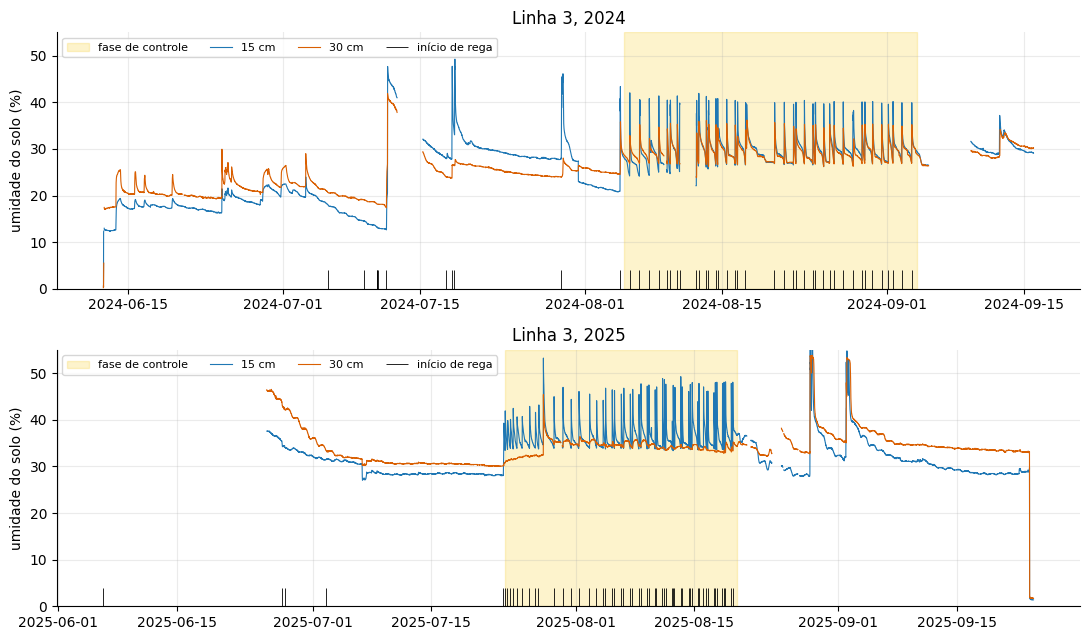

In [11]:
fig, eixos = plt.subplots(2, 1, figsize=(11, 6.5))
for ax, ano in zip(eixos, ANOS):
    b, r = base[ano], regas[ano]
    ini, fim = map(pd.Timestamp, FASE_CONTROLE[ano])
    ax.axvspan(ini, fim, color="#f5c400", alpha=.2, label="fase de controle")
    ax.plot(b.index, b.umid_solo_15cm, lw=.8, color="#1f77b4", label="15 cm")
    ax.plot(b.index, b.umid_solo_30cm, lw=.8, color="#d95f02", label="30 cm")
    ax.vlines(r.ini, 0, 4, color="k", lw=.6, label="início de rega")
    ax.set_ylim(0, 55); ax.set_title(f"Linha 3, {ano}"); ax.set_ylabel("umidade do solo (%)")
    ax.legend(ncol=4, loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

**Leitura.** Em 2024 a válvula abre perto de 27 %, medidos pelo sensor de 30 cm (desvio de 0,5 contra 1,5 no de 15 cm).
Em 2025 o limiar sobe para 33,9 % e quem manda é o sensor de 15 cm (desvio de 0,1 contra 1,0). Então **o limiar não é o mesmo nos dois anos e o sensor que decide também muda**.
Treinar com os dois anos misturados pela umidade bruta ia esconder isso, e é um dos motivos de normalizarmos a umidade (seção 9).

Outro ponto: a fase de controle tem 30 dias em 2024 e 28 em 2025, com 38 e 53 regas. O dataset é grande, mas a parte que representa a regra que queremos aprender
é pequena (91 regas no total). O modelo vai ter pouco dado.

Também aparece uma diferença entre o pico e o valor assentado: logo depois da rega o sensor de 15 cm dá um salto grande (uns 13 pontos), porque a água passa
por ele, e em 2 horas a umidade se acomoda num patamar bem mais baixo. Para medir o efeito de uma rega, o valor assentado é o mais confiável.

In [12]:
# a linha 3 gastou menos água que as outras? mesma janela de cada ano
saida = []
for ano in ANOS:
    ini, fim = map(pd.Timestamp, FASE_CONTROLE[ano])
    a = ler(ano, "water_meter")
    for ln, g in a[a.line.between(1, 5)].groupby("line"):
        vol = g.set_index("t").current_volume.sort_index()
        vol = vol[~vol.index.duplicated()]
        dias = (fim - ini) / pd.Timedelta("1D")
        saida.append({"ano": ano, "linha": ln, "litros_por_dia": (vol.asof(fim) - vol.asof(ini)) / dias})
agua = pd.DataFrame(saida).pivot(index="linha", columns="ano", values="litros_por_dia").round(0)
agua

ano,2024,2025
linha,,
1,169.0,34.0
2,125.0,0.0
3,350.0,417.0
4,263.0,23.0
5,62.0,0.0


O medidor não diz a unidade (o README fala em m³, mas 17 mil m³ numa linha de tomate seria impossível, então deve ser litro).
A comparação entre linhas do mesmo ano vale de qualquer forma, e o resultado é o contrário do que o nome "economia de água" sugere:

- Em 2024, a linha 3 gastou mais do que a linha de 100 % do Irriframe (350 contra 263 por dia).
- Em 2025, nesta janela, as linhas 2 e 5 não irrigaram nenhuma vez (as válvulas ficaram fechadas) e as linhas 1 e 4 quase nada (34 e 23 por dia). A linha 3 regou 417 por dia.

Ou seja, **o limiar da linha 3 não é uma regra que poupa água**: nas duas janelas ele regou mais do que o critério do Irriframe. E como não há dado de produtividade,
não dá para dizer se esse gasto a mais valeu a pena. Isso importa para o projeto, porque imitar a regra reproduz também esse excesso. O modelo deve ser avaliado em relação a ela, mas a meta de economizar
água só pode ser testada depois, no nosso vaso.

## 8. Chuva que não foi registrada

O dataset não tem pluviômetro. Em Parma chove no verão (trovoadas), então uma subida de umidade do solo pode ser chuva e não rega. Se
deixarmos isso passar, o modelo aprende "a umidade subiu sozinha" como se fosse efeito de uma irrigação que nunca aconteceu.

**Como detectar nos próprios sensores.** Uma chuva molha todas as linhas ao mesmo tempo. Uma rega molha só uma. Procuramos horas em que
**3 ou mais das 5 linhas** subiram mais de 1,5 ponto em 1 h, sem a válvula da própria linha aberta nas 3 h ao redor.

**Como conferir.** Comparamos com a precipitação de uma fonte independente, a reanálise ERA5 (via Open-Meteo, para as coordenadas da fazenda). Ela não é
um pluviômetro, só uma estimativa para a região, então serve para conferir, não para decidir.

In [13]:
def baixar_era5(nome, lat, lon, ini="2024-05-25", fim="2025-11-10"):
    arq = EXTERNO / f"era5_{nome}.csv"
    if not arq.exists():
        url = ("https://archive-api.open-meteo.com/v1/archive?"
               f"latitude={lat}&longitude={lon}&start_date={ini}&end_date={fim}"
               "&hourly=temperature_2m,relative_humidity_2m,precipitation&timezone=UTC")
        dados = json.load(urllib.request.urlopen(url, timeout=90))
        pd.DataFrame(dados["hourly"]).to_csv(arq, index=False)
    return pd.read_csv(arq, parse_dates=["time"]).set_index("time")

era_parma = baixar_era5("parma", 44.81, 10.27)
era_fortaleza = baixar_era5("fortaleza", -3.73, -38.52)

def dias_de_chuva(ano, subida=1.5, linhas_min=3):
    s = ler(ano, "soil")
    s = s[(s.t.dt.year == ano) & (s.humidity > 10) & (s.humidity <= 100)]
    m = s.assign(t20=s.t.dt.floor("20min")).groupby(["t20", "line"]).humidity.mean().unstack()
    alta = (m.shift(-3) - m).clip(lower=0)                           # subida em 1 h
    v = ler(ano, "valve_controller")
    v = v[v.valve_state == 1].assign(t20=lambda d: d.t.dt.floor("20min"))
    abre = (v.groupby(["t20", "line"]).size().unstack().reindex(m.index).fillna(0) > 0).reindex(columns=m.columns, fill_value=False)
    perto = abre.astype(float).rolling(19, center=True, min_periods=1).max() > 0   # +-3 h da válvula
    livre = alta.where(~perto)
    n = (livre >= subida).sum(axis=1)
    dia = n[n >= linhas_min].groupby(lambda t: t.date()).max()
    return pd.Series(dia.values, index=pd.to_datetime(dia.index), name="linhas_que_subiram")

chuva_era = era_parma.precipitation.resample("D").sum()
deteccao = {}
for ano in ANOS:
    d = dias_de_chuva(ano).to_frame()
    d["era5_mm"] = chuva_era.reindex(d.index).values
    deteccao[ano] = d
    print(f"{ano}: dias detectados pelos sensores = {len(d)}")
    print(d.round(1).to_string()); print()

# a reanálise acusou chuva forte (>= 10 mm) e os sensores marcaram esse dia (ou um vizinho)?
for ano in ANOS:
    b = base[ano]
    fortes = chuva_era[b.index.min().floor("D"):b.index.max().floor("D")]
    fortes = fortes[fortes >= 10]
    marcados = deteccao[ano].index
    achou = [bool((np.abs((marcados - dia).days) <= 1).any()) for dia in fortes.index]
    print(f"{ano}: {len(fortes)} dias com ERA5 >= 10 mm dentro da janela ativa, e os sensores marcaram {sum(achou)} deles")
    print(f"      dos {len(marcados)} dias marcados pelos sensores, {int((deteccao[ano].era5_mm >= 10).sum())} tiveram >= 10 mm na reanálise")

2024: dias detectados pelos sensores = 7
            linhas_que_subiram  era5_mm
t20                                    
2024-06-13                   3      0.9
2024-06-15                   3      0.0
2024-06-24                   5     32.0
2024-06-25                   5     18.5
2024-07-03                   5      2.1
2024-09-05                   5     11.6
2024-09-12                   5     72.4



2025: dias detectados pelos sensores = 5
            linhas_que_subiram  era5_mm
t20                                    
2025-07-02                   3      0.4
2025-07-28                   4     29.2
2025-08-25                   3      0.5
2025-08-28                   5     12.0
2025-09-01                   5      0.0

2024: 7 dias com ERA5 >= 10 mm dentro da janela ativa, e os sensores marcaram 5 deles
      dos 7 dias marcados pelos sensores, 4 tiveram >= 10 mm na reanálise
2025: 8 dias com ERA5 >= 10 mm dentro da janela ativa, e os sensores marcaram 2 deles
      dos 5 dias marcados pelos sensores, 2 tiveram >= 10 mm na reanálise


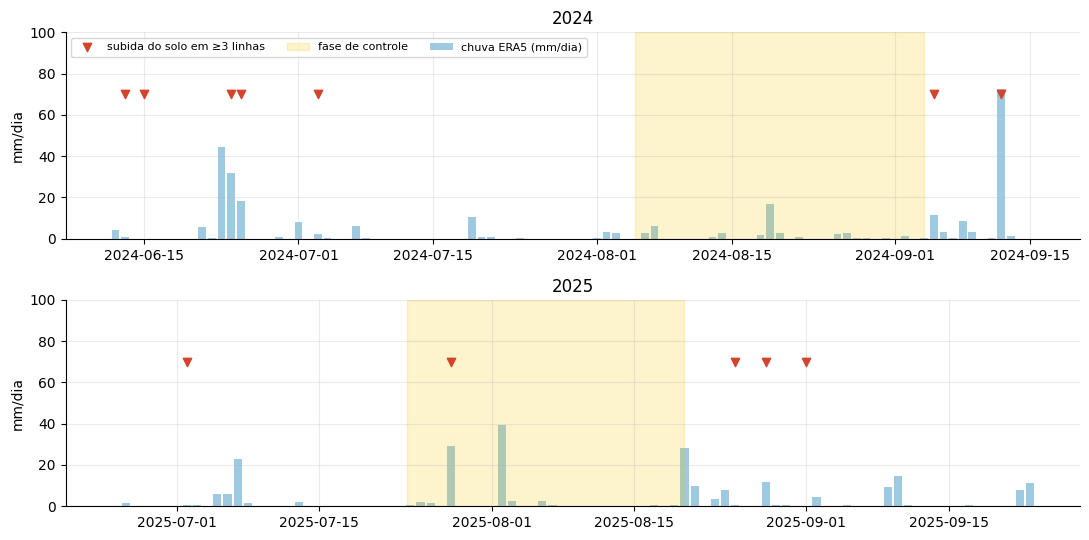

In [14]:
fig, eixos = plt.subplots(2, 1, figsize=(11, 5.5), sharey=True)
for ax, ano in zip(eixos, ANOS):
    b = base[ano]
    dd = chuva_era[b.index.min().floor("D"):b.index.max().floor("D")]
    ax.bar(dd.index, dd.values, color="#9ecae1", label="chuva ERA5 (mm/dia)")
    ax.scatter(deteccao[ano].index, np.full(len(deteccao[ano]), 70), marker="v", color="#d2452c", zorder=3, label="subida do solo em ≥3 linhas")
    ini, fim = map(pd.Timestamp, FASE_CONTROLE[ano])
    ax.axvspan(ini, fim, color="#f5c400", alpha=.2, label="fase de controle")
    ax.set_title(str(ano)); ax.set_ylabel("mm/dia"); ax.set_ylim(0, 100)
eixos[0].legend(ncol=3, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

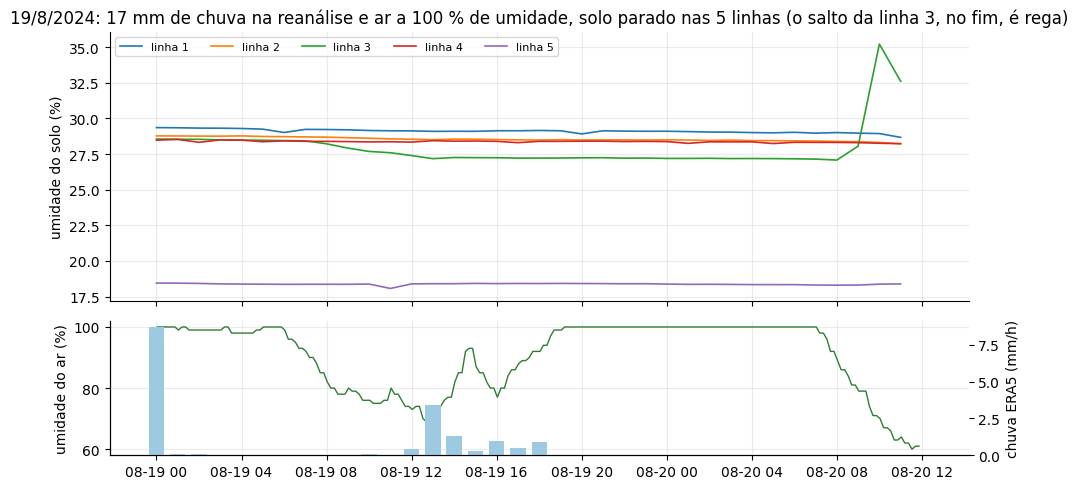

In [15]:
# um dia em que a reanálise diz que choveu forte (17 mm) e o solo não reagiu: umidade das 5 linhas, ar e chuva
ini, fim = pd.Timestamp("2024-08-19 00:00"), pd.Timestamp("2024-08-20 12:00")
s = ler(2024, "soil")
s = s[(s.t >= ini) & (s.t <= fim) & (s.humidity > 10) & (s.humidity <= 100)]
m = s.assign(h=s.t.dt.floor("h")).groupby(["h", "line"]).humidity.mean().unstack()
e = ler(2024, "environmental").set_index("t").sort_index()[ini:fim]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for ln in m.columns:
    a1.plot(m.index, m[ln], lw=1.2, label=f"linha {ln}")
a1.set_ylabel("umidade do solo (%)"); a1.legend(ncol=5, fontsize=8)
a1.set_title("19/8/2024: 17 mm de chuva na reanálise e ar a 100 % de umidade, solo parado nas 5 linhas (o salto da linha 3, no fim, é rega)")
a2.plot(e.index, e.humidity, color="#2e7d32", lw=1)
a2.set_ylabel("umidade do ar (%)")
a3 = a2.twinx(); a3.bar(era_parma.precipitation[ini:fim].index, era_parma.precipitation[ini:fim].values, width=.03, color="#9ecae1")
a3.set_ylabel("chuva ERA5 (mm/h)"); a3.grid(False)
plt.tight_layout(); plt.show()

O que dá para concluir:

- A concordância com a reanálise é parcial nos dois sentidos. Dos 15 dias com 10 mm ou mais na reanálise, os sensores marcaram 7. Dos 12 dias marcados pelos sensores, 6 tiveram 10 mm ou mais.
  Os outros 6 dias marcados tiveram de 0 a 2 mm na reanálise, o que pode ser chuva local que o modelo regional não pegou ou rega manual no campo inteiro. Em qualquer caso a umidade subiu sem a válvula, então esses dias entram como suspeitos.
- Também há muitos dias em que a reanálise acusa chuva forte e o solo **não reage**. Na figura, 17 mm no dia 19/8/2024: a umidade do ar vai a 100 % e o solo fica parado nas cinco linhas. A água não chegou ao sensor
  (cobertura do solo, gotejamento sob plástico ou chuva local diferente da estimada). Para o modelo isso é bom, porque o que importa é a água que o sensor viu, mas quer dizer que a reanálise **não serve sozinha** para filtrar dias.
- **Um dia marcado cai dentro das fases de controle**: 28/07/2025, com 4 linhas subindo e 29 mm na reanálise. Nesse dia a válvula da linha 3 ficou parada (entre as regas de 27/07 às 15 h e de 29/07 às 10 h não houve nenhuma).
- **Os limites da detecção foram escolhidos olhando esse equilíbrio.** Testamos subidas de 1, 1,5 e 2 pontos por hora e de 2, 3 e 4 linhas. Com 1 ponto e 2 linhas são 58 dias marcados, só 10 com 10 mm ou mais na reanálise,
  e 13 dias da fase de controle seriam marcados. Com 1,5 ponto e 3 linhas, o que usamos, são 12 dias marcados (6 com 10 mm ou mais) e só 2 dias (28 e 29/07/2025) caem na fase de controle. Com 4 linhas são 8 dias (os mesmos 6).
  Limites mais frouxos acrescentam dias sem chuva confirmada e apagam dados bons. Mais rígidos que o nosso não mudam a fase de controle.
- **O corte de 10 mm na reanálise** é nosso, para dizer "choveu o bastante para molhar o solo". Os sensores marcaram 8 de 25 dias com 5 mm ou mais, 7 de 15 com 10 mm ou mais e 4 de 7 com 20 mm ou mais.
  Quanto maior a chuva, mais vezes o solo reage, o que sustenta a detecção.

Regra adotada: **marcar o dia e o dia seguinte** como `chuva_suspeita` e deixar o notebook de modelagem decidir se usa ou não esses dias. Aplicada à fase de controle, ela tira só dois dias de 2025 (28 e 29/07). A coluna fica na tabela final.

## 9. Umidade do solo em escala relativa (e o sensor de 7 cm)

Três razões para não usar a umidade bruta do dataset no modelo:

1. O sensor deles (EM500, em % de umidade volumétrica) e o nosso (capacitivo, em % relativa entre o ar e a água) não medem na mesma escala.
2. O limiar foi 27 % em 2024 e 33,9 % em 2025, na mesma fazenda.
3. Nosso sensor fica a 7 cm, não a 15 nem a 30.

A ideia é usar uma escala que tenha o mesmo sentido nos dois sistemas, ancorada em dois pontos que se medem em qualquer sensor:

- `L` (limiar): a umidade em que a válvula abriu.
- `P` (patamar): a umidade em que o solo se acomoda cerca de 2 horas depois da rega (não o pico, que é um salto passageiro).

Para `P` usamos a média entre 90 e 150 minutos depois do início da rega. O sensor de 15 cm cai rápido logo depois do pico (3,2 pontos entre 60 e 120 minutos nos dois anos) e depois fica mais lento,
mas não existe um patamar perfeitamente plano: entre 2 h e 3 h ele ainda perde 1,6 ponto em 2024 e 1,7 em 2025. Então `P` é uma âncora de escala, e usar 3 h em vez de 2 h mudaria `P` em 27 % a 36 % da faixa `P - L`.
Isso estica ou comprime a escala de `u`, mas não muda a ordem dos valores.

Chamamos de **índice de umidade** `u = (umidade - L) / (P - L)`. Com `u = 0` o solo está na hora de regar e com `u = 1` acabou de ser regado.
Na nossa estação, depois do plantio, basta medir esses dois pontos no vaso (o valor em que decidimos regar e o valor logo depois de regar) e o modelo se aplica sem
depender da calibração do fabricante.

In [16]:
refs = []
for ano in ANOS:
    b, r = base[ano], regas[ano]
    ini, fim = map(pd.Timestamp, FASE_CONTROLE[ano])
    c = r[(r.ini >= ini) & (r.ini <= fim)]
    for prof in (15, 30):
        L = c[f"umid_{prof}_antes"].median()
        P = c[f"assentada_{prof}"].median()
        refs.append({"ano": ano, "prof_cm": prof, "L_limiar": L, "P_assentado": P, "faixa_P_menos_L": P - L})
refs = pd.DataFrame(refs).round(1)
refs

,ano,prof_cm,L_limiar,P_assentado,faixa_P_menos_L
0,2024,15,26.8,32.8,6.0
1,2024,30,26.9,31.8,4.9
2,2025,15,33.9,38.5,4.6
3,2025,30,33.9,34.0,0.1


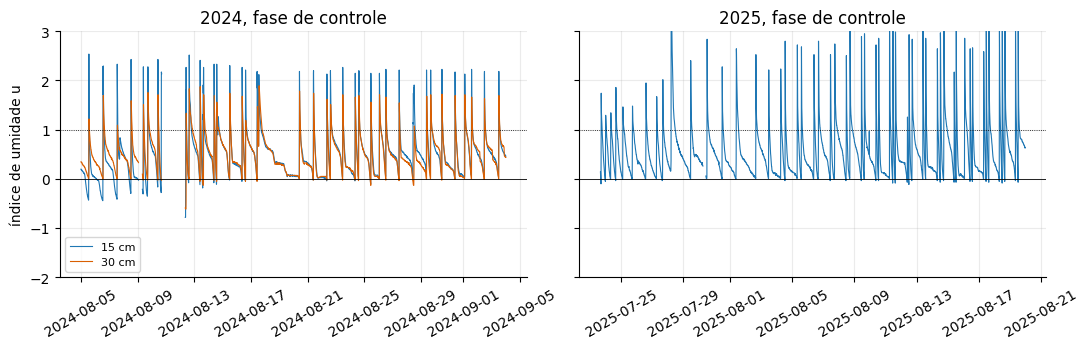

In [17]:
REF = refs.set_index(["ano", "prof_cm"])
for ano in ANOS:
    b = base[ano]
    for prof in (15, 30):
        L, P = REF.loc[(ano, prof), ["L_limiar", "P_assentado"]]
        b[f"u_{prof}cm"] = (b[f"umid_solo_{prof}cm"] - L) / (P - L) if (P - L) >= 1 else np.nan   # sensor que não reage à rega não serve

fig, eixos = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, ano in zip(eixos, ANOS):
    b = base[ano][base[ano].fase == "controle"]
    ax.plot(b.index, b.u_15cm, lw=.8, color="#1f77b4", label="15 cm")
    ax.plot(b.index, b.u_30cm, lw=.8, color="#d95f02", label="30 cm")
    ax.axhline(0, color="k", lw=.6); ax.axhline(1, color="k", lw=.6, ls=":")
    ax.set_title(f"{ano}, fase de controle"); ax.set_ylim(-2, 3); ax.tick_params(axis="x", rotation=30)
eixos[0].set_ylabel("índice de umidade u"); eixos[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**O que isso resolve e o que não resolve.**

- Resolve a diferença de escala entre anos e entre sensores: nos dois anos o sensor de 15 cm passa a ter o mesmo sentido, `u = 0` é "regar", `u = 1` é "recém regado".
- A faixa `P - L` do sensor de 15 cm é parecida nos dois anos (6,0 e 4,6 pontos). O de 30 cm em 2025 **quase não reage à rega** (0,1 ponto), então não calculamos o índice dele nesse ano (fica vazio). O corte em 1 ponto separa esse 0,1 dos 4,6 a 6,0 do sensor de 15 cm. Vamos
  usar só o sensor de 15 cm como substituto do nosso.
- **Não resolve a profundidade.** A 7 cm o solo seca mais rápido e responde mais depressa à rega do que a 15 cm. Tentamos estimar o fator de tempo
  comparando as taxas de secagem de 15 e 30 cm (seção 11), mas a razão entre elas muda muito de um ano para o outro, então extrapolar para 7 cm seria chute.
  A proposta é tratar a escala de tempo como um parâmetro: o modelo prevê em unidades de `u`, e nas primeiras semanas de vaso medimos a secagem real e ajustamos o fator.

## 10. O clima de Parma serve para Fortaleza?

O sensor de ar do dataset está em Parma (clima temperado). A estação vai ficar em Fortaleza (tropical, quente o ano todo, estação seca no
segundo semestre). Se o modelo usar temperatura e umidade do ar, ele só vale se a faixa de valores for parecida.

Não temos dados de Fortaleza medidos por nós, então usamos a reanálise ERA5 (a mesma fonte da seção 8) para as mesmas datas das fases de controle. Antes disso, uma checagem:
a reanálise de Parma bate com o sensor da fazenda?

In [18]:
def clima_janela(ano):
    ini, fim = map(pd.Timestamp, FASE_CONTROLE[ano])
    e = ler(ano, "environmental").set_index("t").sort_index()[ini:fim]
    sensor = e[["temperature", "humidity"]].resample("h").mean().rename(columns={"temperature": "T", "humidity": "UR"})
    p = era_parma[ini:fim].rename(columns={"temperature_2m": "T", "relative_humidity_2m": "UR"})
    f = era_fortaleza[ini:fim].rename(columns={"temperature_2m": "T", "relative_humidity_2m": "UR"})
    out = {}
    for nome, d, fuso in (("Parma, sensor da fazenda", sensor, "Europe/Rome"), ("Parma, ERA5", p, "Europe/Rome"),
                          ("Fortaleza, ERA5", f, "America/Fortaleza")):
        d = d.dropna(subset=["T", "UR"]).copy()
        d["VPD"] = vpd(d["T"], d["UR"])
        d["hora"] = d.index.tz_localize("UTC").tz_convert(fuso).hour
        d["ano"] = ano
        out[nome] = d
    return out

clima = {nome: pd.concat([clima_janela(a)[nome] for a in ANOS]) for nome in clima_janela(2024)}

tab = []
for nome, d in clima.items():
    amp = d["T"].groupby([d.index.date]).agg(lambda x: x.max() - x.min()).mean()
    tab.append({"série": nome, "temp. média (°C)": d["T"].mean(), "amplitude diária (°C)": amp,
                "temp. 0-5 h": d[d.hora.between(0, 5)]["T"].mean(), "temp. 12-16 h": d[d.hora.between(12, 16)]["T"].mean(),
                "umid. ar média (%)": d.UR.mean(), "VPD médio (kPa)": d.VPD.mean(), "VPD p90 (kPa)": d.VPD.quantile(.9)})
tab = pd.DataFrame(tab).set_index("série").round(1)
print(tab.to_string())

j = pd.concat([clima["Parma, sensor da fazenda"]["T"], clima["Parma, ERA5"]["T"]], axis=1, keys=["sensor", "era5"], sort=True).dropna()
print(f"\nParma: correlação sensor x ERA5 (temperatura horária) = {j.corr().iloc[0, 1]:.2f}. "
      f"ERA5 fica {(j.era5 - j.sensor).mean():.1f} °C abaixo do sensor na média")
# os valores de Fortaleza ficam dentro da faixa que o modelo veria no treino (percentis 1 a 99 do sensor de Parma)?
ref, fz = clima["Parma, sensor da fazenda"], clima["Fortaleza, ERA5"]
for var in ("T", "UR", "VPD"):
    lo, hi = ref[var].quantile([.01, .99])
    print(f"{var}: {fz[var].between(lo, hi).mean():.0%} das horas de Fortaleza caem dentro da faixa de Parma ({lo:.1f} a {hi:.1f})")
chuva_f = era_fortaleza.precipitation
print("chuva em Fortaleza nas mesmas datas (mm):", {a: round(float(chuva_f[FASE_CONTROLE[a][0]:FASE_CONTROLE[a][1]].sum()), 1) for a in ANOS})
print("hora do pico de VPD:", {n: int(d.groupby("hora").VPD.mean().idxmax()) for n, d in clima.items()})

                          temp. média (°C)  amplitude diária (°C)  temp. 0-5 h  temp. 12-16 h  umid. ar média (%)  VPD médio (kPa)  VPD p90 (kPa)
série                                                                                                                                            
Parma, sensor da fazenda              26.9                   16.2         20.9           33.6                64.3              1.6            3.5
Parma, ERA5                           25.8                   11.0         22.2           30.2                63.7              1.4            2.9
Fortaleza, ERA5                       26.9                    6.4         25.1           29.5                69.8              1.1            2.1

Parma: correlação sensor x ERA5 (temperatura horária) = 0.90. ERA5 fica -1.2 °C abaixo do sensor na média
T: 100% das horas de Fortaleza caem dentro da faixa de Parma (16.0 a 39.2)
UR: 100% das horas de Fortaleza caem dentro da faixa de Parma (32.9 a 100.0)
VPD: 100% d

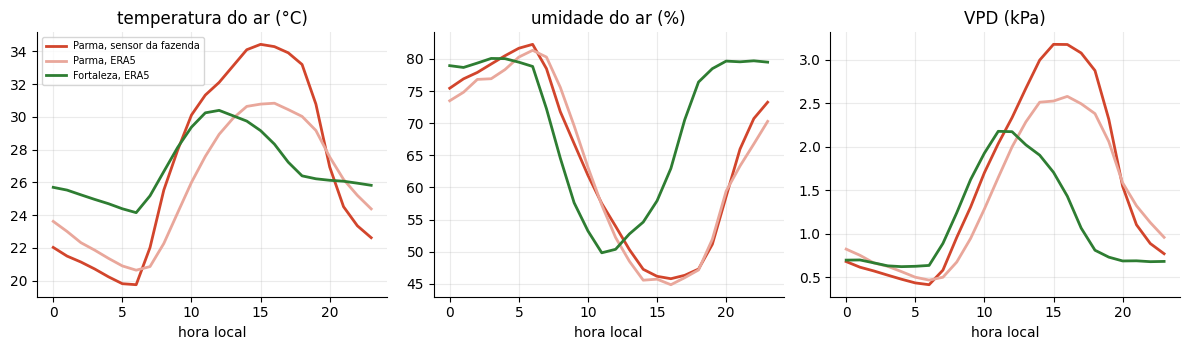

In [19]:
fig, eixos = plt.subplots(1, 3, figsize=(12, 3.6))
cores = {"Parma, sensor da fazenda": "#d2452c", "Parma, ERA5": "#e9a79b", "Fortaleza, ERA5": "#2e7d32"}
for ax, (var, rotulo) in zip(eixos, (("T", "temperatura do ar (°C)"), ("UR", "umidade do ar (%)"), ("VPD", "VPD (kPa)"))):
    for nome, d in clima.items():
        ax.plot(range(24), d.groupby("hora")[var].mean(), color=cores[nome], lw=2, label=nome)
    ax.set_xlabel("hora local"); ax.set_title(rotulo)
eixos[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Leitura:**

- Na média os dois lugares se parecem (temperatura de 26 a 27 °C e umidade do ar de 64 a 70 %). Quem só olhasse a média diria que "dá para usar direto".
- O que muda é o **ciclo do dia**. Em Parma a temperatura varia uns 16 °C entre madrugada e tarde (medida pelo sensor da fazenda), e em Fortaleza, uns 6 °C. As madrugadas de Fortaleza
  são bem mais quentes (25 °C contra 21 °C) e as tardes, mais frescas (29,5 °C contra 33,6 °C). O VPD acompanha: o p90 é 3,5 kPa em Parma e 2,1 em Fortaleza, o VPD médio é um pouco menor (1,1 contra 1,4 a 1,6)
  e o pico acontece por volta das 15 h em Parma e das 11 h em Fortaleza.
- A reanálise de Parma acompanha o sensor da fazenda (correlação de 0,90), mas fica 1,2 °C abaixo na média e suaviza os picos (amplitude de 11 °C contra 16 °C). Então os números de Fortaleza, que também
  vêm da reanálise, provavelmente subestimam a amplitude real de lá. A diferença real entre os dois climas pode ser maior do que a mostrada.
- Chuva em Fortaleza nessas datas: 2,5 mm em 2024 e 34,5 mm em 2025. Estamos na estação seca. Em Parma há trovoadas, o que reforça separar os dias de chuva.

**O que isso significa para o modelo:**

1. Usar **VPD** em vez de temperatura e umidade separadas: ele resume a demanda de água do ar de forma que vale nos dois climas.
2. Não usar a temperatura absoluta nem a hora do relógio como entrada sem cuidado, porque o ciclo de Fortaleza é diferente (até o horário do pico muda). Quem mede a secagem de verdade é o próprio solo.
3. Treinar com os dados de Parma e **recalibrar com os primeiros dias do nosso vaso**. Todas as horas de Fortaleza caem dentro da faixa de valores que Parma tem (ver as porcentagens acima), então
   o modelo não vai extrapolar, mas vai ver combinações pouco comuns no treino, como madrugada quente com ar úmido.

## 11. O que faz o solo secar

Para um modelo prever "quando vai chegar a hora de regar", o que importa é a velocidade de secagem. Medimos quanto o sensor de 15 cm (e o de 30 cm) perdem
em 1 hora, só nos períodos sem rega nem uma rega recente (3 h antes) e sem dia de chuva suspeito, dentro das fases de controle.

      horas_analisadas  queda 15 cm (pontos/h)  queda 30 cm (pontos/h)  razão 15 cm / 30 cm  corr. queda 15 cm x VPD
ano                                                                                                                 
2024               501                    0.24                    0.19                 1.31                     0.50
2025               333                    0.28                    0.01                27.12                     0.49
2024: queda no sensor de 15 cm entre 9 h e 17 h = 0.62 pontos/h e entre 0 h e 5 h = 0.12 (5.4 vezes)
2025: queda no sensor de 15 cm entre 9 h e 17 h = 0.57 pontos/h e entre 0 h e 5 h = 0.16 (3.5 vezes)


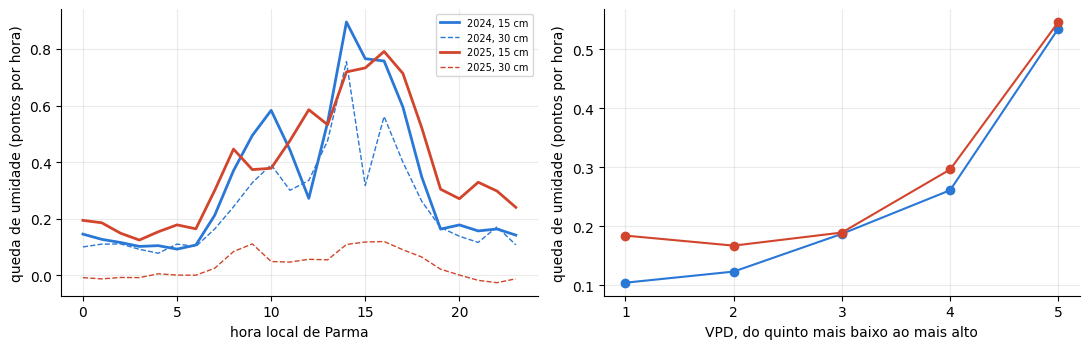

In [20]:
def secagem(ano):
    b = base[ano].copy()
    perto = b.valvula.astype(float).rolling(25, center=True, min_periods=1).max() > 0     # +-2 h de uma rega
    for prof in (15, 30):
        b[f"queda_{prof}cm"] = -(b[f"umid_solo_{prof}cm"].shift(-6) - b[f"umid_solo_{prof}cm"])   # queda em 1 h
    dias = b.index.normalize()
    marcados = deteccao[ano].index                                   # dias de chuva detectados na seção 8
    chuva = dias.isin(marcados) | dias.isin(marcados + pd.Timedelta("1D"))
    ok = (b.fase == "controle") & ~perto & ~perto.shift(-6, fill_value=True) & ~chuva
    return b[ok]

sec = {ano: secagem(ano) for ano in ANOS}
linhas = []
for ano in ANOS:
    d = sec[ano]
    linhas.append({"ano": ano, "horas_analisadas": len(d) // 6,
                   "queda 15 cm (pontos/h)": d.queda_15cm.mean(), "queda 30 cm (pontos/h)": d.queda_30cm.mean(),
                   "razão 15 cm / 30 cm": d.queda_15cm.mean() / d.queda_30cm.mean(),
                   "corr. queda 15 cm x VPD": d.queda_15cm.corr(d.vpd_kpa)})
print(pd.DataFrame(linhas).set_index("ano").round(2).to_string())
for ano in ANOS:
    d = sec[ano]
    dia, noite = d[d.hora_local.between(9, 17)].queda_15cm.mean(), d[d.hora_local.between(0, 5)].queda_15cm.mean()
    print(f"{ano}: queda no sensor de 15 cm entre 9 h e 17 h = {dia:.2f} pontos/h e entre 0 h e 5 h = {noite:.2f} ({dia / noite:.1f} vezes)")

fig, eixos = plt.subplots(1, 2, figsize=(11, 3.6))
for ano, cor in zip(ANOS, ("#2a78d6", "#d2452c")):
    d = sec[ano]
    eixos[0].plot(range(24), d.groupby("hora_local").queda_15cm.mean(), color=cor, lw=2, label=f"{ano}, 15 cm")
    eixos[0].plot(range(24), d.groupby("hora_local").queda_30cm.mean(), color=cor, lw=1, ls="--", label=f"{ano}, 30 cm")
    q = pd.qcut(d.vpd_kpa, 5, duplicates="drop")
    eixos[1].plot(range(len(q.cat.categories)), d.groupby(q, observed=True).queda_15cm.mean().values, "o-", color=cor, label=f"{ano}, 15 cm")
eixos[0].set_xlabel("hora local de Parma"); eixos[0].set_ylabel("queda de umidade (pontos por hora)")
eixos[0].legend(fontsize=7)
eixos[1].set_xlabel("VPD, do quinto mais baixo ao mais alto"); eixos[1].set_xticks(range(5)); eixos[1].set_xticklabels(["1", "2", "3", "4", "5"])
eixos[1].set_ylabel("queda de umidade (pontos por hora)")
plt.tight_layout(); plt.show()

**Leitura.**

- O solo seca de 3,5 a 5,4 vezes mais depressa de dia (9 h às 17 h) do que de madrugada (0 h às 5 h). A secagem acompanha o ciclo da luz, da temperatura e do VPD: a correlação entre a queda por hora e o VPD é de 0,5 nos dois anos, e a queda média
  sobe de 0,10 para 0,53 ponto por hora entre a menor e a maior faixa de VPD em 2024 e de 0,18 para 0,55 em 2025, quase todo o aumento nas duas faixas mais altas.
- A queda média no sensor de 15 cm é parecida nos dois anos (0,24 e 0,28 ponto por hora), mesmo com limiares diferentes. Isso dá confiança em usar o sensor de 15 cm como referência.
- O sensor de 30 cm seca menos, e em 2025 quase nada. A razão entre os dois é de 1,3 em 2024 e de 27 em 2025, ou seja, instável. Por isso não extrapolamos para 7 cm só
  com essa razão (seção 9).

Para o modelo, a consequência é que **o tempo até a próxima rega não é constante**: depende da hora e da demanda do ar. Prever "umidade futura" ou "falta quanto para `u = 0`" com VPD e hora tem sentido. Uma regra
fixa de intervalo não.

## 12. A tabela final

Juntamos os dois anos, colocamos as marcações (fase, chuva suspeita, buraco) e salvamos. O notebook de modelagem escolhe as linhas pelas marcações, e por isso não apagamos nenhum dado aqui.

In [21]:
final = []
for ano in ANOS:
    b = base[ano].copy()
    susp = set(deteccao[ano].index.date)
    dia_utc = pd.Series(b.index.date, index=b.index)
    ontem = pd.Series((b.index - pd.Timedelta("1D")).date, index=b.index)
    b["chuva_suspeita"] = dia_utc.isin(susp) | ontem.isin(susp)      # o dia e o dia seguinte
    b["buraco"] = b.umid_solo_15cm.isna() | b.temp_ar.isna()
    final.append(b)
final = pd.concat(final)

colunas = ["ano", "hora_local", "fase", "umid_solo_15cm", "umid_solo_30cm", "u_15cm", "u_30cm", "temp_solo_15cm", "temp_solo_30cm",
           "temp_ar", "umid_ar", "vpd_kpa", "valvula", "litros", "chuva_suspeita", "buraco"]
final = final[colunas].round({"umid_solo_15cm": 2, "umid_solo_30cm": 2, "u_15cm": 3, "u_30cm": 3, "temp_solo_15cm": 1,
                              "temp_solo_30cm": 1, "temp_ar": 1, "umid_ar": 1, "vpd_kpa": 3, "litros": 1})
final.to_csv(PROCESSADO / "linha3_10min.csv")

controle = final[(final.fase == "controle") & ~final.buraco & ~final.chuva_suspeita]
print(f"tabela completa: {len(final)} linhas de 10 min ({final.groupby('ano').size().to_dict()})")
print(f"fase de controle, sem buraco e sem chuva suspeita: {len(controle)} linhas ({len(controle) / 144:.0f} dias)")
print(f"  por ano: {controle.groupby('ano').size().to_dict()}")
c = final[final.fase == "controle"]
print(f"fase de controle completa: {len(c) / 144:.0f} dias. Perdidos por buraco: {c.buraco.sum() / 144:.1f} dias, "
      f"por chuva suspeita (sem contar os buracos): {(c.chuva_suspeita & ~c.buraco).sum() / 144:.1f} dia(s)")
final.head(3)

tabela completa: 26928 linhas de 10 min ({2024: 13824, 2025: 13104})
fase de controle, sem buraco e sem chuva suspeita: 7664 linhas (53 dias)
  por ano: {2024: 4042, 2025: 3622}
fase de controle completa: 57 dias. Perdidos por buraco: 2.1 dias, por chuva suspeita (sem contar os buracos): 2.0 dia(s)


,ano,hora_local,fase,umid_solo_15cm,umid_solo_30cm,u_15cm,u_30cm,temp_solo_15cm,temp_solo_30cm,temp_ar,umid_ar,vpd_kpa,valvula,litros,chuva_suspeita,buraco
t,,,,,,,,,,,,,,,,
2024-06-12 00:00:00,2024,2,outra,NaN,NaN,NaN,NaN,24.7,24.2,17.6,81.0,0.382,False,0.0,False,True
2024-06-12 00:10:00,2024,2,outra,NaN,NaN,NaN,NaN,24.7,24.2,17.5,86.0,0.280,False,0.0,False,True
2024-06-12 00:20:00,2024,2,outra,NaN,NaN,NaN,NaN,24.7,24.2,17.3,90.0,0.197,False,0.0,False,True


### O que ficou decidido

| Pergunta | Decisão | Motivo |
|---|---|---|
| Anos | 2024 e 2025 | únicos com uma linha controlada por umidade do solo e com sensores a 15 e 30 cm |
| Linha | 3 | o motivo de cada rega está nos dados (o solo chegou a um valor) |
| Sensores | 15 cm como substituto do nosso, e 30 cm só para análise | o de 30 cm quase não responde em 2025 |
| Qual sensor é qual | `901b4b` = 15 cm, `2f2ba9` = 30 cm | temperatura do solo e tempo de resposta à rega concordam |
| Período útil | só as fases de controle (30 dias em 2024 e 28 em 2025, cerca de 53 dias sem buraco e sem chuva suspeita) | antes disso são testes e regas manuais |
| Umidade | índice `u` entre o limiar e o patamar 2 h depois da rega | limiar e escala diferem entre anos e entre sensores |
| Chuva | marcar o dia e o dia seguinte (`chuva_suspeita`) | solo molhado sem válvula, e a reanálise sozinha não serve para filtrar |
| Clima | usar VPD e recalibrar com o vaso de Fortaleza | o ciclo do dia de Parma é muito mais forte que o de Fortaleza |
| Profundidade (7 cm) | tratar a escala de tempo como parâmetro a ajustar | a razão 15/30 cm não é estável para extrapolar |

### Limites desta análise

- Poucos dados úteis: 91 regas e 58 dias de controle estável (cerca de 53 sem buracos nem chuva suspeita).
- O limiar da linha 3 regou mais que o critério do Irriframe nas duas janelas, então imitá-lo não garante economia de água.
- A "resposta certa" é a regra de limiar da linha 3, não uma medida de produtividade.
- O limiar e o sensor que manda mudaram de um ano para o outro. O índice `u` ameniza isso, mas não elimina.
- Fortaleza só foi comparada por reanálise, não por medição nossa.
- A profundidade de cada sensor foi inferida, não informada pelo dataset.

### Próximo passo

O notebook de modelagem usa essa tabela e separa treino e teste por ano (treinar em 2024 e testar em 2025, e o contrário).